In [1]:
#Note:
#In this tutorial you will learn how to use CAC Python library for building a non-intrusive reduced basis (NI-RB) surrogate model
#for a 2D spatio-temporal problem
#
#The test case is 2D transient heat conduction in a square plate: a hot spot is placed in the plate at t = 0 and cools down by diffusion
#    dT/dt = kappa * (d2T/dx2 + d2T/dy2),   on [0,1] x [0,1],   T = 0 on all boundaries
#    T(x, y, t=0) = exp(-((x - x0)^2 + (y - 0.5)^2) / (2 * sigma^2))
#
#We have 2 uncertain parameters:  kappa (thermal diffusivity) in [0.002, 0.02] and x0 (horizontal position of the hot spot) in [0.25, 0.75]
#and 1 time parameter:            t in [0, 2]
#
#NI-RB works in two phases:
#IMPORTANT: run generate_data.ipynb first! It samples the parameters with SALib (Latin Hypercube Sampling),
#runs the simulator, and saves the snapshots as .npy files in the data folder. This notebook only loads them
#
#Offline phase: (1) run the full simulator for some parameter combinations (snapshots) --> done in generate_data.ipynb
#               (2) compress the snapshots with proper orthogonal decomposition (POD) into a small set of basis functions
#               (3) train a neural network that maps (t, kappa, x0) --> reduced basis coefficients; hyperparameters are tuned automatically with BOHB
#Online phase:  for any new (t, kappa, x0), the network predicts the coefficients and the full 2D field is reconstructed in milliseconds
#
#Check Degen et al. (2023) - Perspectives of physics-based machine learning strategies for geoscientific applications governed by partial differential equations
#
#The whole tutorial runs on a laptop CPU in a few minutes

In [2]:
#Import external libraries
import numpy
import os
import shutil
import time
import matplotlib.pyplot as plt

In [3]:
#Import CAC python library
from cac import model, trainer, utilities

2026-10-19 15:10:27.843722: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-19 15:10:27.864222: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
#Create folders for data and results
#Note that, the NIRB trainer needs an absolute path to save its scaling factors, basis, and trained model
data_path    = os.path.abspath('data')
results_path = os.path.abspath('results')
os.makedirs(data_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)

In [5]:
#Load the snapshots generated by generate_data.ipynb
#
#The parameter arrays have the size (number of samples, number of parameters) --> columns: kappa, x0
#The output arrays have the size (number of samples, number of time steps, number of degrees of freedom)
#This is the format required by the spatio-temporal NI-RB in CAC
if(not os.path.isfile(data_path + '/training_outputs.npy')):
    err_msg = "Data not found. Please run generate_data.ipynb first!"
    raise FileNotFoundError(err_msg)

x     = numpy.load(data_path + '/grid_x.npy')
y     = numpy.load(data_path + '/grid_y.npy')
times = numpy.load(data_path + '/times.npy')
nx, ny, nt = len(x), len(y), len(times)

training_parameters = numpy.load(data_path + '/training_parameters.npy')
training_outputs    = numpy.load(data_path + '/training_outputs.npy')
test_parameters     = numpy.load(data_path + '/test_parameters.npy')
test_outputs        = numpy.load(data_path + '/test_outputs.npy')

print("Grid: " + str(nx) + " x " + str(ny) + ", time steps: " + str(nt))
print("Training parameters: " + str(training_parameters.shape) + ", training outputs: " + str(training_outputs.shape))
print("Test parameters: " + str(test_parameters.shape) + ", test outputs: " + str(test_outputs.shape))

Grid: 32 x 32, time steps: 21
Training parameters: (40, 2), training outputs: (40, 21, 1024)
Test parameters: (10, 2), test outputs: (10, 21, 1024)


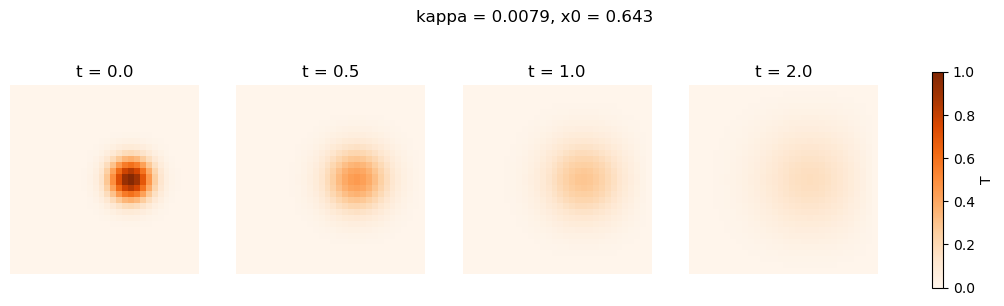

In [6]:
#Show one training simulation at 4 different times
sample = 0
fig, axs = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, kk in zip(axs, [0, 5, 10, 20]):
    im = ax.imshow(training_outputs[sample, kk, :].reshape(ny, nx), origin='lower', extent=[0,1,0,1], cmap='Oranges', vmin=0, vmax=1)
    ax.set_title('t = ' + str(round(times[kk], 2)))
    ax.axis('off')
fig.colorbar(im, ax=axs, shrink=0.8, label='T')
fig.suptitle('kappa = ' + str(round(training_parameters[sample,0], 4)) + ', x0 = ' + str(round(training_parameters[sample,1], 3)))
plt.show()

In [7]:
#IMPORTANT: arranging the inputs
#
#For spatio-temporal problems, time is treated as an input of the network. Hence, every row of the input array is (t, kappa, x0)
#CAC arranges the outputs internally in a "time-major" order:
#    row 0           --> time step 0, sample 0
#    row 1           --> time step 0, sample 1
#    ...
#    row Ns          --> time step 1, sample 0
#    ...
#so the input array must follow exactly the same order --> size (number of time steps * number of samples, 1 + number of parameters)
#We also put time in the first column (this is required if you later want to use ml_type='bt')
def arrange_inputs(parameters, times):

    arranged = []
    for t in times:              #outer loop: time
        for p in parameters:     #inner loop: samples
            arranged.append([t, *p])

    return numpy.asarray(arranged)

training_inputs = arrange_inputs(training_parameters, times)
test_inputs     = arrange_inputs(test_parameters, times)
print("Training inputs: " + str(training_inputs.shape))
print("Test inputs: " + str(test_inputs.shape))

Training inputs: (840, 3)
Test inputs: (210, 3)


In [8]:
#We are now ready for the offline phase
#
#First, we create an NIRB object and tell it where to save all results (scaling factors, basis, trained model)
nirb = trainer.NIRB()
nirb.save_path = results_path

In [9]:
#Defining the training and test set
#
#For this purpose, we use this function: nirb.define_set(training_input_array=None, training_output_array=None, test_input_array=None, test_output_array=None)
#The inputs are scaled with a standard scaler and the outputs with a min-max scaler
#The scaling factors are saved as "inputs_standard_scaling_factor.npy" and "outputs_minmax_scaling_factor.npy"
#If the output array has 3 dimensions (samples, time, dofs), the function automatically treats the problem as spatio-temporal
nirb.define_set(training_input_array=training_inputs, training_output_array=training_outputs,
                test_input_array=test_inputs, test_output_array=test_outputs)

In [10]:
#Reducing the output with proper orthogonal decomposition (POD)
#
#For this purpose, we use this function: nirb.reduce_output(params_cut_off=None, time_cut_off=None, is_large=False, scaled=False, memory_limit='2GB')
#For spatio-temporal problems, a two-stage POD is applied: first in time for each sample (time_cut_off), then across all samples (params_cut_off)
#The cut offs are given in percent of the retained information (energy of the singular values). 99.999 is a good starting point
#is_large=True uses dask for snapshot matrices that do not fit into memory
#scaled=True applies an additional standard scaling on the reduced coefficients (recommended, it makes the network training easier)
#The basis is saved as "output_basis.npy"
#
#For a temporal (or steady-state) problem without time dependence, only fill params_cut_off and give a 2D output array (samples, dofs)
nirb.reduce_output(params_cut_off=99.999, time_cut_off=99.999, is_large=False, scaled=False, memory_limit='2GB')

print("Number of degrees of freedom: " + str(nx * ny))
print("Number of reduced basis functions: " + str(nirb.output_basis.shape[0]))

Output dimension: 40
Number of degrees of freedom: 1024
Number of reduced basis functions: 40


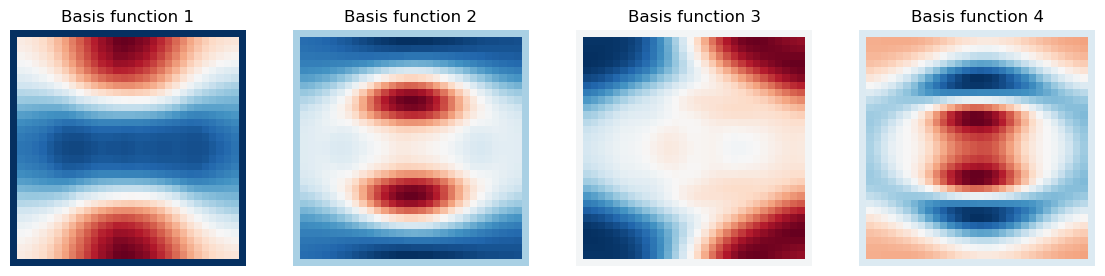

In [11]:
#Show the first 4 reduced basis functions (POD modes)
#These are the spatial "building blocks": every solution is approximated as a weighted sum of them
fig, axs = plt.subplots(1, 4, figsize=(14, 3.5))
for ii, ax in enumerate(axs):
    ax.imshow(nirb.output_basis[ii, :].reshape(ny, nx), origin='lower', extent=[0,1,0,1], cmap='RdBu_r')
    ax.set_title('Basis function ' + str(ii + 1))
    ax.axis('off')
plt.show()

In [12]:
#Training with automatic hyperparameter optimization
#
#For this purpose, we use this function: nirb.execute(ml_type='nn', neurons_in_layer1=None, neurons_in_layer2=None, epoch=None, learning_rate=None,
#                                                     activation_function='sigmoid', optimization_steps=30, loss_function='mse', distributed=False)
#ml_type selects the regression model: 'nn' (feed-forward neural network), 'resnet', 'gpr' (Gaussian process), or 'bt' (branch-trunk network)
#neurons_in_layer1, neurons_in_layer2, epoch, learning_rate are given as [lower bound, upper bound] --> BOHB searches inside these ranges
#The batch size is also optimized automatically
#optimization_steps is the maximum budget of BOHB --> a larger value means more trials, e.g., 9 gives ~20 trials, 30 gives ~70 trials
#If you install the GPU version of this library, you can set "distributed=True" which will activate Horovod library to allow training with GPU
#
#The best model is saved as "trained_model.tf" and its hyperparameters as "trained_model_hyperparameters.npy"
#with the order: [neurons layer 1, neurons layer 2, epochs, learning rate, batch size, training time, test error]
#
#Note: this cell takes a few minutes on a CPU. For a quick run, use optimization_steps=3
start = time.time()
nirb.execute(ml_type='nn',
             neurons_in_layer1=[5, 64],
             neurons_in_layer2=[5, 64],
             epoch=[200, 1000],
             learning_rate=[1E-4, 1E-2],
             activation_function='tanh',
             optimization_steps=9,
             loss_function='mse',
             distributed=False)
print("Offline training time: " + str(round(time.time() - start, 2)) + " s")


Begin optimization: 
INFO:tensorflow:Assets written to: /home/santoso1/simulation/cac_tutorial/tutorial_3/results/experiments/0.00118916_trained_model.tf/assets


INFO:tensorflow:Assets written to: /home/santoso1/simulation/cac_tutorial/tutorial_3/results/experiments/0.00118916_trained_model.tf/assets


Current error: 0.00118916
INFO:tensorflow:Assets written to: /home/santoso1/simulation/cac_tutorial/tutorial_3/results/experiments/0.00052859_trained_model.tf/assets


INFO:tensorflow:Assets written to: /home/santoso1/simulation/cac_tutorial/tutorial_3/results/experiments/0.00052859_trained_model.tf/assets


Current error: 0.00052859
INFO:tensorflow:Assets written to: /home/santoso1/simulation/cac_tutorial/tutorial_3/results/experiments/0.00469291_trained_model.tf/assets


...

Current error: 0.00079514


Current error: 0.00047744


Current error: 0.01843385


Current error: 0.01660001
End optimization


Final L2-norm for full solutions: 0.00271301
Offline training time: 302.97 s


In [14]:
#Show the selected hyperparameters
hyperparameters = numpy.load(results_path + '/trained_model_hyperparameters.npy')
print("Neurons in layer 1: " + str(int(hyperparameters[0])))
print("Neurons in layer 2: " + str(int(hyperparameters[1])))
print("Epochs: " + str(int(hyperparameters[2])))
print("Learning rate: " + str(hyperparameters[3]))
print("Batch size: " + str(int(hyperparameters[4])))

Neurons in layer 1: 51
Neurons in layer 2: 51
Epochs: 936
Learning rate: 0.008015972312966918
Batch size: 319


In [16]:
#Online phase
#
#The online phase only needs the files in the results folder, so you can run it later in a new session without re-training
#
#For this purpose, we use the class: model.online_nirb(ml_type, save_path)
#load_existing_model()                        --> loads "trained_model.tf"
#load_output_basis(data_driven=False)         --> loads "output_basis.npy"
#load_scaling_factor(inner_scaled=False)      --> loads the scaling factors; set inner_scaled=True because we used scaled=True in reduce_output
online = model.online_nirb('nn', results_path)
online.load_existing_model()
online.load_output_basis(data_driven=False)
online.load_scaling_factor(inner_scaled=False)

Model: "sequential_20"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_80 (Dense)            (None, 3)                 12        
                                                                 
 dense_81 (Dense)            (None, 51)                204       
                                                                 
 dense_82 (Dense)            (None, 51)                2652      
                                                                 
 dense_83 (Dense)            (None, 40)                2080      
                                                                 
Total params: 4948 (19.33 KB)
Trainable params: 4948 (19.33 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None


 dense_80 (Dense)            (None, 3)                 12        


 dense_81 (Dense)            (None, 51)                204       


 dense_82 (Dense)            (None, 51)                2652      


 dense_83 (Dense)            (None, 40)                2080      


Total params: 4948 (19.33 KB)


Trainable params: 4948 (19.33 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


None


In [17]:
#Making prediction for completely new parameter combinations
#
#For this purpose, we use this function: online.predict(prediction_input_array, prediction_output_array=None)
#The input array must be arranged in the same time-major order as before
#The output has the size (number of time steps * number of samples, number of degrees of freedom), also time-major
#
#Here we use the prediction set from generate_data.ipynb: 3 LHS samples that were never used in the offline phase
#Their simulator results (reference) are only used for comparison
prediction_parameters = numpy.load(data_path + '/prediction_parameters.npy')
reference             = numpy.load(data_path + '/prediction_outputs.npy')
prediction_inputs     = arrange_inputs(prediction_parameters, times)

start = time.time()
predicted = online.predict(prediction_inputs)
nirb_time = time.time() - start

#Re-arrange the prediction from time-major rows back to (samples, time, dofs), the same format as the reference
predicted = predicted.reshape(nt, len(prediction_parameters), nx * ny).transpose(1, 0, 2)

#For real simulators (e.g., Lattice-Boltzmann runs of hours), the NI-RB prediction time stays in the millisecond range
print("NI-RB time for " + str(len(prediction_inputs)) + " fields: " + str(round(nirb_time, 4)) + " s")
print("Predicted outputs: " + str(predicted.shape))

NI-RB time for 63 fields: 0.0353 s
Predicted outputs: (3, 21, 1024)


In [18]:
#Error calculation
#
#We calculate our own errors here, since the error option of online.predict relies on an older scikit-learn version
#Note that, the "Final L2-norm" printed by nirb.execute is the RMSE averaged over every degree of freedom (scikit-learn convention), hence it differs slightly
rmse = numpy.sqrt(numpy.mean((predicted - reference)**2))
relative_error = numpy.linalg.norm(predicted - reference) / numpy.linalg.norm(reference)
print("RMSE: " + str(round(rmse, 6)))
print("Relative L2 error: " + str(round(100 * relative_error, 2)) + " %")

numpy.savetxt(results_path + '/prediction_error.txt', [rmse, relative_error])

RMSE: 0.00477
Relative L2 error: 6.03 %


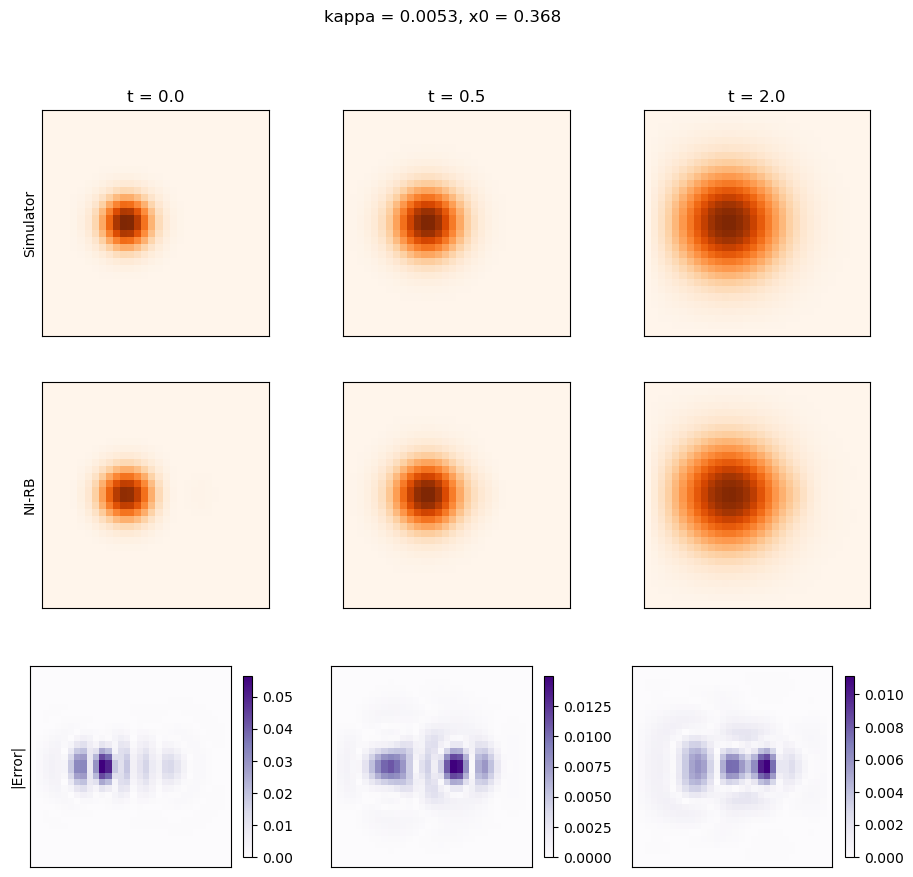

In [19]:
#Visual comparison: reference simulation vs NI-RB prediction vs absolute error
sample = 0
time_steps = [0, 5, 20]

fig, axs = plt.subplots(3, len(time_steps), figsize=(11, 10))
for jj, kk in enumerate(time_steps):
    ref  = reference[sample, kk, :].reshape(ny, nx)
    pred = predicted[sample, kk, :].reshape(ny, nx)
    vmax = ref.max()
    axs[0, jj].imshow(ref,  origin='lower', extent=[0,1,0,1], cmap='Oranges', vmin=0, vmax=vmax)
    axs[1, jj].imshow(pred, origin='lower', extent=[0,1,0,1], cmap='Oranges', vmin=0, vmax=vmax)
    im = axs[2, jj].imshow(numpy.abs(ref - pred), origin='lower', extent=[0,1,0,1], cmap='Purples')
    fig.colorbar(im, ax=axs[2, jj], shrink=0.8)
    axs[0, jj].set_title('t = ' + str(round(times[kk], 2)))
for ii, name in enumerate(['Simulator', 'NI-RB', '|Error|']):
    axs[ii, 0].set_ylabel(name)
for ax in axs.flatten():
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle('kappa = ' + str(round(prediction_parameters[sample,0], 4)) + ', x0 = ' + str(round(prediction_parameters[sample,1], 3)))
plt.show()

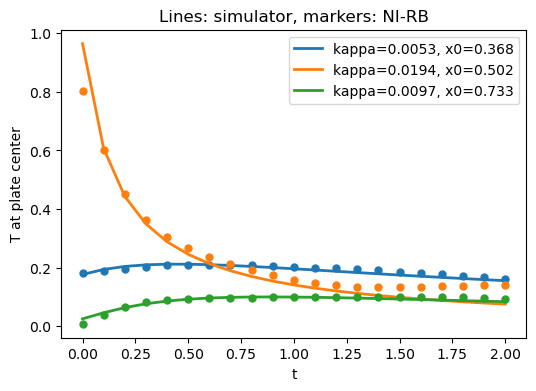

In [20]:
#Temperature at the plate center over time for the 3 new parameter combinations
center = (ny // 2) * nx + nx // 2

plt.figure(figsize=(6,4))
for ss in range(len(prediction_parameters)):
    line, = plt.plot(times, reference[ss, :, center], linewidth=2,
                     label='kappa=' + str(round(prediction_parameters[ss,0], 4)) + ', x0=' + str(round(prediction_parameters[ss,1], 3)))
    plt.plot(times, predicted[ss, :, center], 'o', markersize=5, color=line.get_color())
plt.xlabel('t')
plt.ylabel('T at plate center')
plt.title('Lines: simulator, markers: NI-RB')
plt.legend()
plt.show()

In [21]:
#What to change for your own problem:
#1. In generate_data.ipynb, change the SALib problem (names, bounds) and replace heat_simulator with your simulator
#   (or save your own snapshots as .npy) --> parameters (samples, parameters), outputs (samples, time steps, dofs)
#2. Build the inputs with arrange_inputs --> rows (t, parameter 1, parameter 2, ...) in time-major order
#3. Tune the cut offs in reduce_output and the search ranges in execute
#4. Use model.online_nirb with the results folder for fast predictions